# Day 3 - Practical task: Tree ensembles on breast cancer data

1. Load the breast cancer dataset from scikit-learn
2. Train Decision Tree, Random Forest and Gradient Boosting (same split, same metrics)
3. Tune Random Forest hyperparameters and report the best combination
4. Compare ROC-AUC and F1 for all models

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, f1_score, roc_curve

## 1. Load data

In [25]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target

print(X.shape)
print(y.value_counts())  # 0 = malignant, 1 = benign

(569, 30)
target
1    357
0    212
Name: count, dtype: int64


## 2. One split for all models + train them

The classes are a bit unbalanced, so I used stratify=y to keep the same ratio in train and test.

In [26]:
# stratify keeps the same malignant/benign ratio in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=7
)

# all models with default settings first
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=7),
    'Random Forest': RandomForestClassifier(random_state=7),
    'Gradient Boosting': GradientBoostingClassifier(random_state=7),
}

# ROC-AUC needs probabilities, F1 needs predicted labels
def evaluate(model):
    proba = model.predict_proba(X_test)[:, 1]  # probability of class 1
    pred = model.predict(X_test)
    return {'ROC-AUC': roc_auc_score(y_test, proba), 'F1': f1_score(y_test, pred)}

scores = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    scores[name] = evaluate(model)

# models as rows
pd.DataFrame(scores).T.round(4)

,ROC-AUC,F1
Decision Tree,0.9756,0.9834
Random Forest,0.9947,0.9609
Gradient Boosting,0.9941,0.9659


## 3. Tune Random Forest

Grid search with 5-fold CV on the training set only, scored by ROC-AUC. The test set is only used at the end.

In [27]:
# 2 * 3 * 2 * 2 = 24 combinations, each checked with 5-fold CV
param_grid = {
    'n_estimators': [100, 300],
    'max_depth': [None, 5, 10],
    'min_samples_leaf': [1, 3],
    'max_features': ['sqrt', 0.5],
}

search = GridSearchCV(
    RandomForestClassifier(random_state=7),
    param_grid,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1,  # use all CPU cores
)
# only train data here, test set stays unseen
search.fit(X_train, y_train)

print('Best params:', search.best_params_)
print('Best CV AUC:', round(search.best_score_, 4))

Best params: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}
Best CV AUC: 0.9905


## 4. Compare all models

In [28]:
# best_estimator_ is already refit on the whole train set with the best params
models['Random Forest (tuned)'] = search.best_estimator_
scores['Random Forest (tuned)'] = evaluate(search.best_estimator_)

results = pd.DataFrame(scores).T.sort_values('ROC-AUC', ascending=False)
results.round(4)

,ROC-AUC,F1
Random Forest (tuned),0.9958,0.9721
Random Forest,0.9947,0.9609
Gradient Boosting,0.9941,0.9659
Decision Tree,0.9756,0.9834


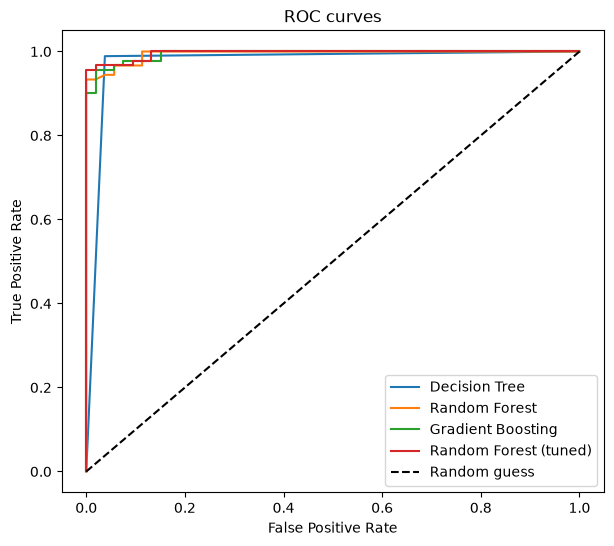

In [29]:
# ROC curves on the test set
plt.figure(figsize=(7, 6))
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curves')
plt.legend()
plt.show()

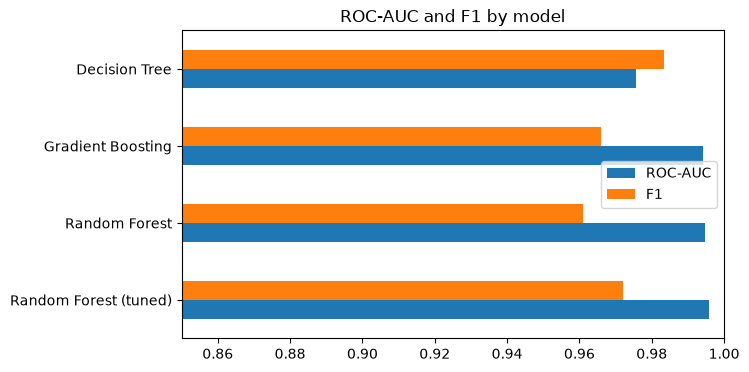

In [30]:
results.plot(kind='barh', figsize=(7, 4))
plt.xlim(0.85, 1.0)
plt.title('ROC-AUC and F1 by model')
plt.show()

In [31]:
from sklearn.metrics import confusion_matrix

# confusion matrix for the tuned RF, rows = real, columns = predicted
best_rf = search.best_estimator_
cm = pd.DataFrame(
    confusion_matrix(y_test, best_rf.predict(X_test)),
    index=['real malignant', 'real benign'],
    columns=['pred malignant', 'pred benign'],
)
cm

,pred malignant,pred benign
real malignant,51,2
real benign,3,87


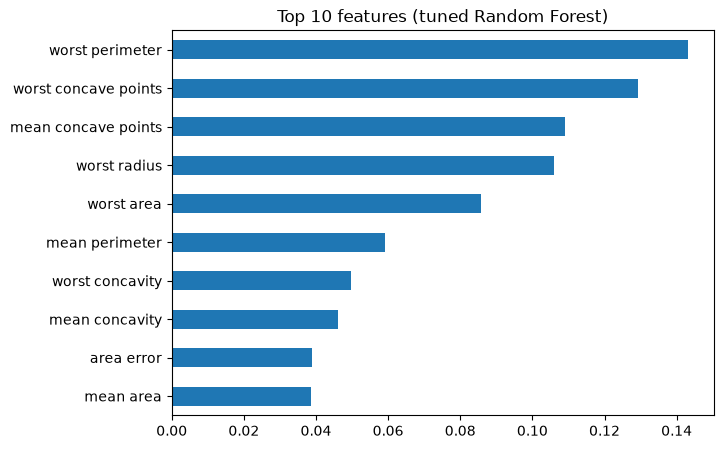

In [32]:
# which features the tuned RF uses the most
importance = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values()
importance.tail(10).plot(kind='barh', figsize=(7, 5))
plt.title('Top 10 features (tuned Random Forest)')
plt.show()

## Conclusion

The best Random Forest settings were n_estimators=300, max_depth=None, max_features='sqrt' and min_samples_leaf=1 (CV ROC-AUC 0.9905). That's basically the default settings with more trees, so Random Forest already works well out of the box here.

By ROC-AUC all three ensembles are around 0.995, and the tuned Random Forest is the best (0.996). The single Decision Tree is clearly lower (0.976), because one tree gives almost only 0 or 1 probabilities, so it can't rank patients well.

The Decision Tree has the best F1 (0.983), but the test set is small (143 patients), so one or two mistakes change F1 a lot. I think this is luck with the split, not a better model. F1 also uses a fixed 0.5 threshold, while ROC-AUC checks all thresholds.

The confusion matrix shows the tuned Random Forest missed only 2 of 53 malignant cases. The most important features are worst perimeter, worst concave points and mean concave points, so the size and shape of the tumour matter the most. This also explains why all scores are so high, the classes are easy to separate.

Two things to keep in mind. In this dataset 1 means benign, so F1 here is about finding healthy patients (for malignant I would use pos_label=0). Also, only the Random Forest was tuned, the other two use default settings, so the comparison isn't completely fair.

Overall, I would pick the tuned Random Forest. It has the highest ROC-AUC and stable cross-validation results.